Loaded (2208, 37) JSE tickers across (2208, 37) trading days.

--- Standalone Monthly Spearman Rank IC ---
momentum_12_1    | Mean IC: +0.0520 | IC IR: +0.19
reversal_1m      | Mean IC: +0.0434 | IC IR: +0.16
low_volatility   | Mean IC: -0.0233 | IC IR: -0.08

--- Out-of-Sample Walk-Forward Multi-Factor Strategy ---
Combined Mean IC:      +0.0152
Annualized L/S Return: 20.09%
Annualized Volatility: 39.71%
Gross Sharpe Ratio:    0.51


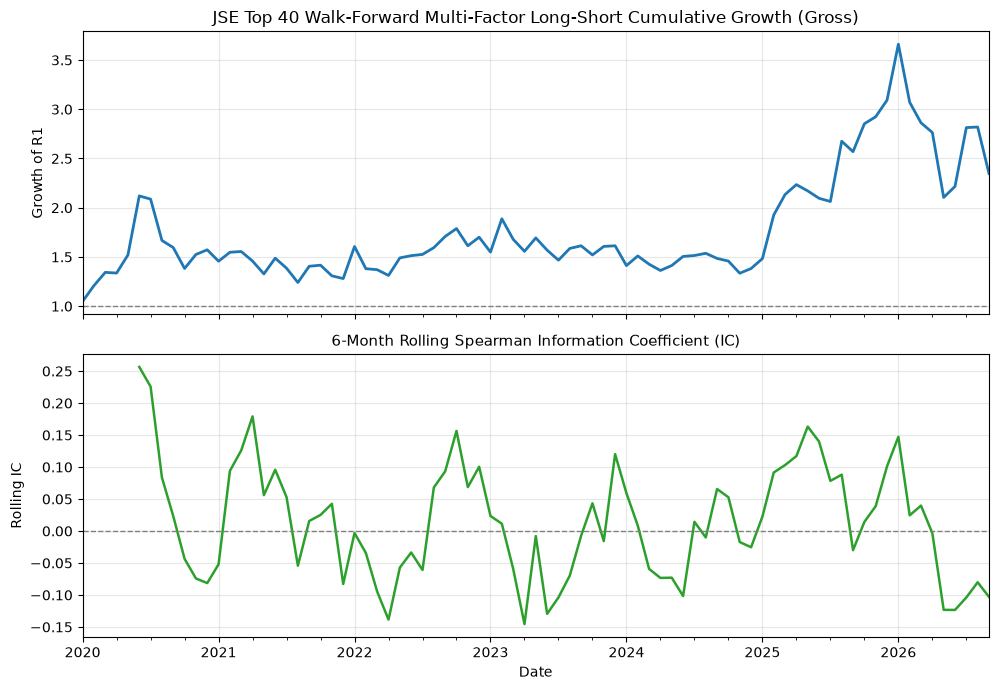

In [ ]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")
from src.data_loader import fetch_jse_prices
from src.factors import compute_monthly_factors
from src.evaluation import compute_monthly_ic, walk_forward_ridge_backtest

# 1. Fetch clean JSE Top 40 historical prices
prices = fetch_jse_prices(start_date="2018-01-01", end_date="2026-11-01")
print(f"Loaded {prices.shape[1]} JSE tickers across {prices.shape[0]} trading days.\n")

# 2. Compute factors TWO ways: global Z-scores vs sector-neutral Z-scores
factors_global = compute_monthly_factors(prices, neutralize=False)
factors_neutral = compute_monthly_factors(prices, neutralize=True)

# 3. Compare standalone ICs side by side
print("--- Standalone Monthly Spearman Rank IC (Global vs Sector-Neutral) ---")
for name in ["momentum_12_1", "reversal_1m", "low_volatility"]:
    ic_g = compute_monthly_ic(factors_global[name], factors_global["forward_return"])
    ic_n = compute_monthly_ic(factors_neutral[name], factors_neutral["forward_return"])
    ir_g = ic_g.mean() / ic_g.std()
    ir_n = ic_n.mean() / ic_n.std()
    print(
        f"{name:16s} | Global IC: {ic_g.mean():+.4f} (IR {ir_g:+.2f})"
        f" | Sector-Neutral IC: {ic_n.mean():+.4f} (IR {ir_n:+.2f})"
    )

# 4. Run both backtests with identical settings (24-month window, alpha=10, top-5)
bt_global = walk_forward_ridge_backtest(factors_global, train_window=24, alpha=10.0, top_n=5)
bt_neutral = walk_forward_ridge_backtest(factors_neutral, train_window=24, alpha=10.0, top_n=5)

def _metrics(bt: pd.DataFrame) -> tuple[float, float, float, pd.Series]:
    ann_return = bt["Long_Short_Return"].mean() * 12
    ann_vol = bt["Long_Short_Return"].std() * np.sqrt(12)
    sharpe = ann_return / ann_vol
    cum = (1 + bt["Long_Short_Return"]).cumprod()
    return ann_return, ann_vol, sharpe, cum

g_ret, g_vol, g_sharpe, g_cum = _metrics(bt_global)
n_ret, n_vol, n_sharpe, n_cum = _metrics(bt_neutral)

print("\n--- Walk-Forward Ridge Backtest: Global vs Sector-Neutral ---")
print(f"{'Metric':<26s} | {'Global':>12s} | {'Sector-Neutral':>15s}")
print(f"{'Combined Mean IC':<26s} | {bt_global['IC'].mean():>+12.4f} | {bt_neutral['IC'].mean():>+15.4f}")
print(f"{'Annualized L/S Return':<26s} | {g_ret:>12.2%} | {n_ret:>15.2%}")
print(f"{'Annualized Volatility':<26s} | {g_vol:>12.2%} | {n_vol:>15.2%}")
print(f"{'Gross Sharpe Ratio':<26s} | {g_sharpe:>12.2f} | {n_sharpe:>15.2f}")

# 5. Plot both equity curves and both rolling ICs
os.makedirs("../results", exist_ok=True)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

g_cum.plot(ax=ax1, label="Global Z-score (v1)", color="#1f77b4", linewidth=2)
n_cum.plot(ax=ax1, label="Sector-Neutral Z-score (v2)", color="#ff7f0e", linewidth=2)
ax1.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax1.set_title("JSE Top 40 Long-Short Cumulative Growth: Global vs Sector-Neutral", fontsize=12)
ax1.set_ylabel("Growth of R1")
ax1.legend()
ax1.grid(alpha=0.3)

bt_global["IC"].rolling(6).mean().plot(ax=ax2, label="Global IC (6m rolling)", color="#1f77b4", linewidth=1.8)
bt_neutral["IC"].rolling(6).mean().plot(ax=ax2, label="Sector-Neutral IC (6m rolling)", color="#ff7f0e", linewidth=1.8)
ax2.axhline(0.0, color="gray", linestyle="--", linewidth=1)
ax2.set_title("6-Month Rolling Combined Signal IC", fontsize=11)
ax2.set_ylabel("Rolling IC")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../results/backtest_comparison.png", dpi=150)
plt.show()